In [68]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import dump

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# from sklearn.datasets import load_digits
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')

RANDOM_STATE = 42
data = pd.read_csv("Social_media_impact_on_life.csv")
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

OUTPUT_DIR = Path('CNN_Vegetable_Classification')
OUTPUT_DIR.mkdir(exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch version:', torch.__version__)
print('Using device:', DEVICE)


PyTorch version: 2.15.0+cpu
Using device: cpu


In [44]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


train_path = r"D:\python_files\python_ai_ml_resources-master\python_ai_ml_resources-master\Vegetable Images\train"
test_path = r"D:\python_files\python_ai_ml_resources-master\python_ai_ml_resources-master\Vegetable Images\test"
val_path = r"D:\python_files\python_ai_ml_resources-master\python_ai_ml_resources-master\Vegetable Images\validation"
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(
    train_path,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_path,
    transform=test_transform
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=test_transform
)
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

class_names = train_dataset.classes
images, y = next(iter(train_loader)) #verify the image and label shape


print('Images shape:', images.shape)
print('Target shape:', y.shape)
print('Pixel value range:', images.min(), 'to', images.max())
print('Classes:', class_names)

Images shape: torch.Size([16, 3, 128, 128])
Target shape: torch.Size([16])
Pixel value range: tensor(0.) to tensor(1.)
Classes: ['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal', 'Broccoli', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Cucumber', 'Papaya', 'Potato', 'Pumpkin', 'Radish', 'Tomato']


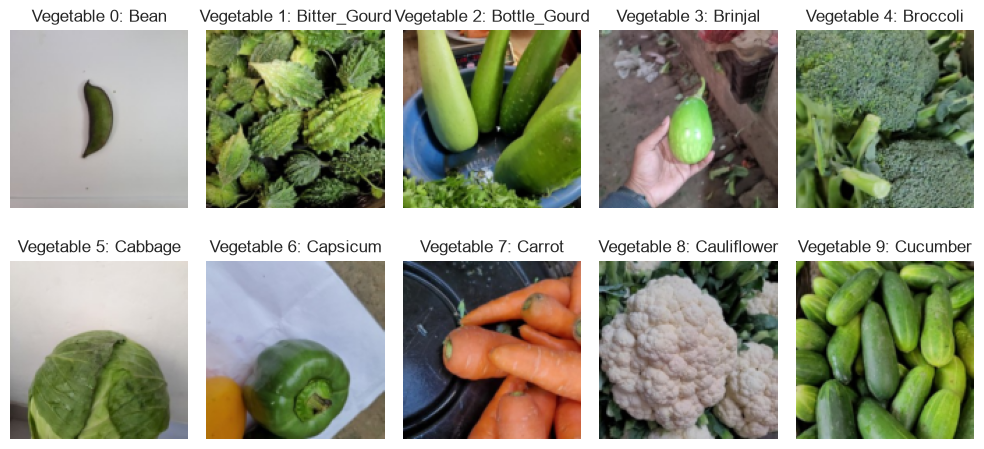

In [45]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.ravel()

for veg in range(10):
    index = train_dataset.targets.index(veg)
    img, _ = train_dataset[index]
    img = img.permute(1, 2, 0).numpy()
    axes[veg].imshow(img)
    axes[veg].set_title(f'Vegetable {veg}: {class_names[veg]}')
    axes[veg].axis('off')

plt.tight_layout()
plt.show()

In [46]:
print('Pixel value range:', images.min(), 'to', images.max())
print('CNN input shape:', images.shape)


Pixel value range: tensor(0.) to tensor(1.)
CNN input shape: torch.Size([16, 3, 128, 128])


In [47]:
import torch.nn.functional as F #load function relu
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        num_classes = len(train_dataset.classes)
               
        self.features = nn.Sequential(
                    nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
                    nn.ReLU(),
                    nn.MaxPool2d(kernel_size=2),
                    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
                    nn.ReLU(),
                    
                )
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(
                   nn.Flatten(),
                   nn.Linear(32 * 4 * 4, 128),
                   nn.ReLU(),
                   nn.Linear(128, num_classes),
               )
       

    def forward(self, x):
        x = self.features(x)
        x = self.adaptive_pool(x)
        x = self.classifier(x)
        return x
        
model = CNN().to(DEVICE)
print(model)


CNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=15, bias=True)
  )
)


In [48]:
example_batch, example_labels = next(iter(train_loader))
example_batch = example_batch.to(DEVICE)
with torch.no_grad():
    example_outputs = model(example_batch)

print('Input batch shape:', example_batch.shape)
print('Output batch shape:', example_outputs.shape)
print('First image raw class scores:')
print(example_outputs[0].cpu().numpy().round(3))
predicted_class = example_outputs[0].argmax().item()
print("Predicted class index:", predicted_class)
class_names = train_dataset.classes
print("Predicted vegetable:", class_names[predicted_class])
actual_class = example_labels[0].item()
print("Actual vegetable:", class_names[actual_class])

Input batch shape: torch.Size([16, 3, 128, 128])
Output batch shape: torch.Size([16, 15])
First image raw class scores:
[ 0.06   0.058 -0.034 -0.011 -0.034 -0.002  0.096  0.08   0.059 -0.076
  0.018 -0.033 -0.042  0.084  0.01 ]
Predicted class index: 6
Predicted vegetable: Capsicum
Actual vegetable: Cabbage


In [49]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print('Loss function:', criterion)
print('Optimizer:', optimizer.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: Adam


In [52]:
def train_one_epoch(model, data_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch_images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

    return total_loss / total, correct / total


def evaluate(model, data_loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch_images, batch_labels in data_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

            total_loss += loss.item() * batch_images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == batch_labels).sum().item()
            total += batch_labels.size(0)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(batch_labels.cpu().numpy())

    return total_loss / total, correct / total, np.array(all_predictions), np.array(all_labels)

history = []
EPOCHS = 25

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    test_loss, test_acc, _, _ = evaluate(model, test_loader, criterion, DEVICE)

    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'train_accuracy': train_acc,
        'test_loss': test_loss,
        'test_accuracy': test_acc,
    })

    if epoch == 1 or epoch % 5 == 0:
        print(
            f'Epoch {epoch:02d} | '
            f'Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f} | '
            f'Test loss: {test_loss:.4f} | Test acc: {test_acc:.4f}'
        )

history_df = pd.DataFrame(history)
history_df.tail()

Epoch 01 | Train loss: 0.1130 | Train acc: 0.9679 | Test loss: 0.1872 | Test acc: 0.9447
Epoch 05 | Train loss: 0.0739 | Train acc: 0.9778 | Test loss: 0.1489 | Test acc: 0.9563
Epoch 10 | Train loss: 0.0485 | Train acc: 0.9845 | Test loss: 0.1430 | Test acc: 0.9640
Epoch 15 | Train loss: 0.0241 | Train acc: 0.9929 | Test loss: 0.1410 | Test acc: 0.9660
Epoch 20 | Train loss: 0.0406 | Train acc: 0.9878 | Test loss: 0.1302 | Test acc: 0.9730
Epoch 25 | Train loss: 0.0175 | Train acc: 0.9955 | Test loss: 0.1435 | Test acc: 0.9727


,epoch,train_loss,train_accuracy,test_loss,test_accuracy
20,21,0.029166,0.990733,0.170319,0.969000
21,22,0.027555,0.992000,0.144727,0.973333
22,23,0.020207,0.993467,0.160316,0.968333
23,24,0.044969,0.987000,0.137996,0.973667
24,25,0.017474,0.995467,0.143453,0.972667


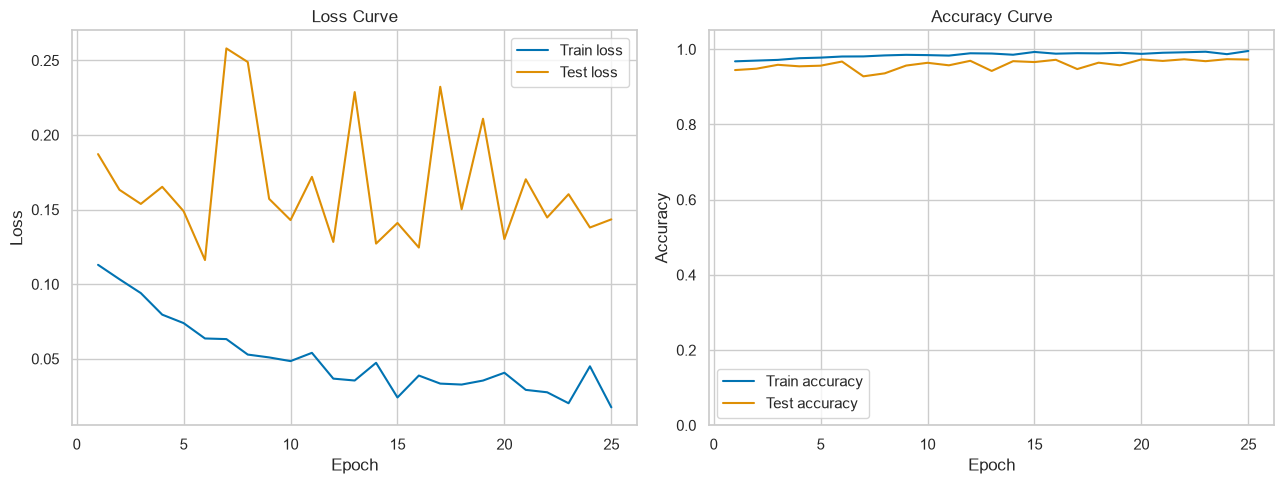

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history_df['epoch'], history_df['train_loss'], label='Train loss')
axes[0].plot(history_df['epoch'], history_df['test_loss'], label='Test loss')
axes[0].set_title('Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history_df['epoch'], history_df['train_accuracy'], label='Train accuracy')
axes[1].plot(history_df['epoch'], history_df['test_accuracy'], label='Test accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1.05)
axes[1].legend() 
 

plt.tight_layout()
plt.show()

In [54]:
test_loss, test_accuracy, cnn_predictions, y_test_array = evaluate(model, test_loader, criterion, DEVICE)

print('Final test loss:', round(test_loss, 4))
print('Final test accuracy:', round(test_accuracy, 4))
print('\nClassification report:')
print(classification_report(y_test_array, cnn_predictions, target_names=class_names))

Final test loss: 0.1435
Final test accuracy: 0.9727

Classification report:
              precision    recall  f1-score   support

        Bean       0.97      0.98      0.97       200
Bitter_Gourd       0.99      0.96      0.98       200
Bottle_Gourd       0.98      0.99      0.99       200
     Brinjal       0.97      0.97      0.97       200
    Broccoli       0.97      0.96      0.96       200
     Cabbage       0.97      0.97      0.97       200
    Capsicum       0.98      0.98      0.98       200
      Carrot       0.97      0.99      0.98       200
 Cauliflower       0.97      0.97      0.97       200
    Cucumber       0.99      0.97      0.98       200
      Papaya       0.97      0.99      0.98       200
      Potato       0.99      1.00      1.00       200
     Pumpkin       0.92      0.95      0.94       200
      Radish       0.99      0.98      0.99       200
      Tomato       0.95      0.90      0.92       200

    accuracy                           0.97      3000
   m

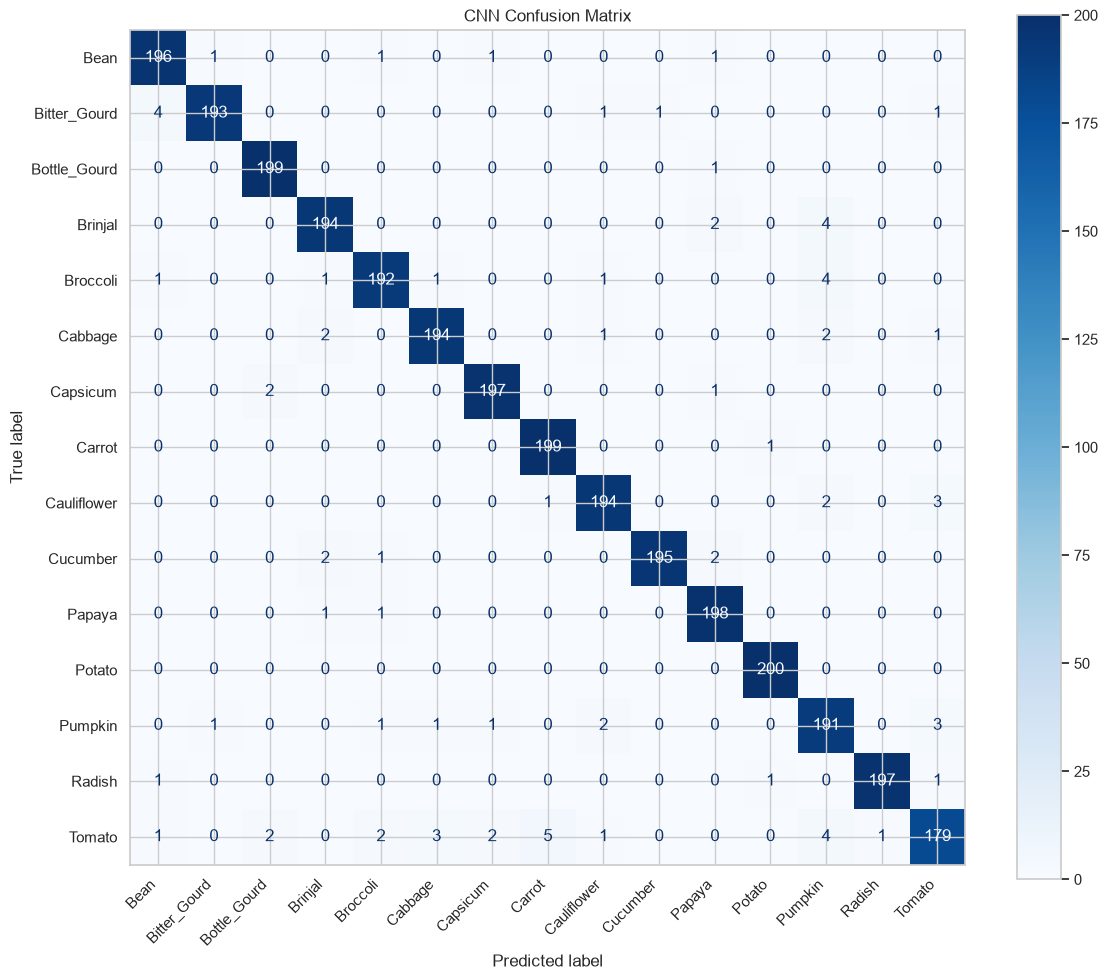

In [58]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test_array,
    cnn_predictions,
    display_labels=class_names,
    cmap='Blues',
    ax=ax,
)
ax.tick_params(axis='x', labelrotation=45)
for label in ax.get_xticklabels():
    label.set_ha('right')
plt.title('CNN Confusion Matrix')
plt.tight_layout()
plt.show()

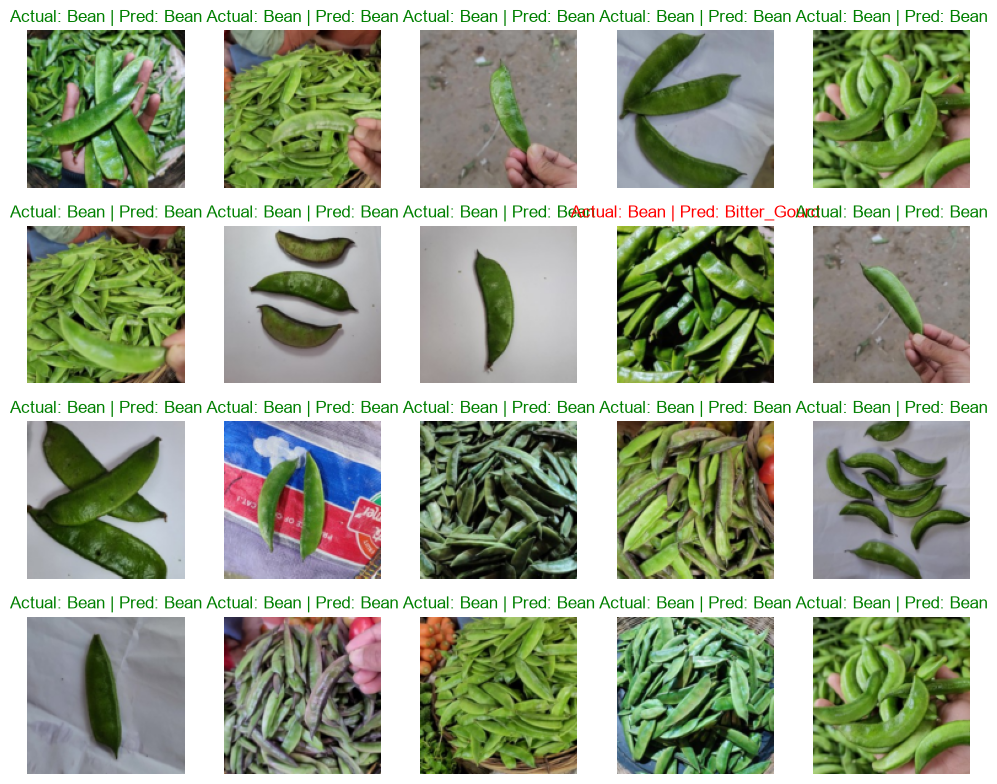

In [60]:
fig, axes = plt.subplots(4, 5, figsize=(10, 8))
axes = axes.ravel()

for index, ax in enumerate(axes):
    if index >= len(cnn_predictions):
        ax.axis('off')
        continue

    image, actual = test_dataset[index]
    pred = cnn_predictions[index]
    ax.imshow(image.permute(1, 2, 0).cpu().numpy())
    color = 'green' if actual == pred else 'red'
    ax.set_title(f'Actual: {class_names[actual]} | Pred: {class_names[pred]}', color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()

Number of wrong predictions: 82


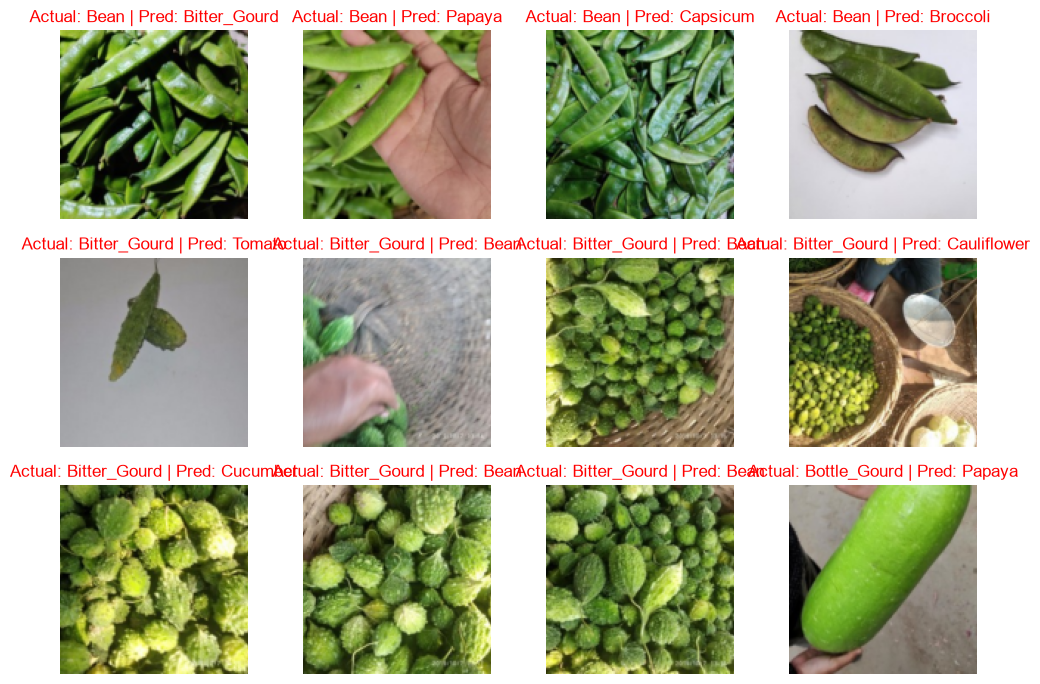

In [66]:
wrong_indices = np.where(cnn_predictions != y_test_array)[0]
print('Number of wrong predictions:', len(wrong_indices))

if len(wrong_indices) > 0:
    n_show = min(12, len(wrong_indices))
    fig, axes = plt.subplots(3, 4, figsize=(10, 7))
    axes = axes.ravel()

    for ax, index in zip(axes, wrong_indices[:n_show]):
        image, actual = test_dataset[index]
        ax.imshow(image.permute(1, 2, 0).cpu().numpy())
        ax.set_title(
            f'Actual: {class_names[int(actual)]} | Pred: {class_names[int(cnn_predictions[index])]}',
            color='red',
        )
        ax.axis('off')

    for ax in axes[n_show:]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print('No wrong predictions on this test split.')

In [69]:
model_path = OUTPUT_DIR / 'vegetable_cnn_model.pth'
history_path = OUTPUT_DIR / 'cnn_training_history.csv'
evaluation_path = OUTPUT_DIR / 'evaluation_report.txt'

torch.save(
    model.state_dict(),
    model_path
)
history_df.to_csv(history_path, index=False)
import json

with open("class_names.json", "w") as f:
    json.dump(train_dataset.classes, f)

report = classification_report(y_test_array, cnn_predictions, target_names=class_names)

with open("evaluation_report.txt", "w") as f:
    f.write(report)
print('Saved PyTorch model weights:', model_path)
print('Saved training history:', history_path)
print('Saved prediction probabilities:', evaluation_path)


Saved PyTorch model weights: CNN_Vegetable_Classification\vegetable_cnn_model.pth
Saved training history: CNN_Vegetable_Classification\cnn_training_history.csv
Saved prediction probabilities: CNN_Vegetable_Classification\evaluation_report.txt
